## Implementation of solution of burger's equation

In [38]:
import numpy as np
from matplotlib import pyplot as plt, cm
from matplotlib import animation

In [39]:
#Initialize domain and mesh
nx = 41
ny = 41
dx = 2 / (nx - 1)
dy = 2 / (ny - 1)
nu = 0.01

X, Y = np.meshgrid(np.linspace(0, 2, nx), np.linspace(0, 2, ny))

#Initialize time
nt = 12
sigma = 0.2
dt = sigma * dx

In [40]:
#Initialize field variable
u = np.ones((ny, nx)) # create a 2D array of ones
v = np.ones((ny, nx)) # create a 2D array of ones

#insert initial conditions
u[int(0.5/dx):int(1/dx+1),int(0.5/dy):int(1/dy+1)] = 2
v[int(0.5/dx):int(1/dx+1),int(0.5/dy):int(1/dy+1)] = 2
U:list = [[u, v, np.sqrt(u**2 + v**2)]] # store the velocity field in a tuple
U_mag = np.sqrt(u**2 + v**2) # compute the magnitude of the velocity field

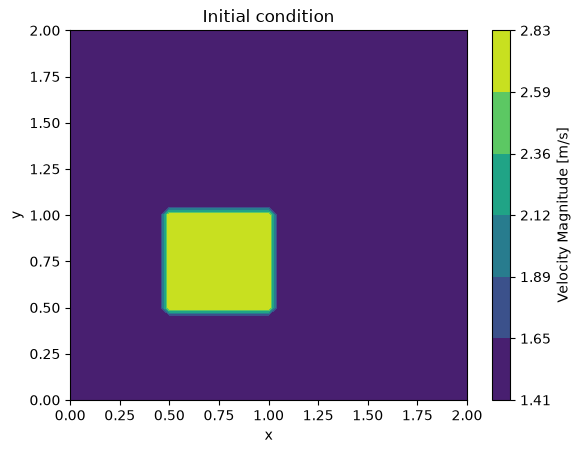

In [41]:
#plot the initial conditionts
fig, ax = plt.subplots()
levels = np.linspace(U_mag.min(), U_mag.max(), 7)
contour = ax.contourf(X, Y, U_mag, levels = levels)
fig.colorbar(contour, ax=ax, label="Velocity Magnitude [m/s]", format="%.2f")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Initial condition")
fig.savefig("initial_condition.png", dpi=300, bbox_inches="tight")
plt.show()

In [42]:
#loop for solution 2D Burgers equation

for n in range(nt + 1):
    un = u.copy()
    vn = v.copy()

    u[1:-1,1:-1] = (u[1:-1,1:-1] - 
                    dt / dx * u[1:-1,1:-1] * (u[1:-1,1:-1] - u[0:-2,1:-1]) -
                    dt / dy * v[1:-1,1:-1] * (u[1:-1,1:-1] - u[1:-1,0:-2]) +
                   nu * dt / dx**2 * (u[2:,1:-1] - 2 * u[1:-1,1:-1] + u[:-2,1:-1]) +
                   nu * dt / dy**2 * (u[1:-1,2:] - 2 * u[1:-1,1:-1] + u[1:-1,:-2]))
    v[1:-1,1:-1] = (v[1:-1,1:-1] - 
                    dt / dx * u[1:-1,1:-1] * (v[1:-1,1:-1] - v[0:-2,1:-1]) -
                    dt / dy * v[1:-1,1:-1] * (v[1:-1,1:-1] - v[1:-1,0:-2]) +
                   nu * dt / dx**2 * (v[2:,1:-1] - 2 * v[1:-1,1:-1] + v[:-2,1:-1]) +
                   nu * dt / dy**2 * (v[1:-1,2:] - 2 * v[1:-1,1:-1] + v[1:-1,:-2]))

    # Apply boundary conditions
    u[0, :] = 1
    u[-1, :] = 1
    u[:, 0] = 1
    u[:, -1] = 1
    
    v[0, :] = 1
    v[-1, :] = 1
    v[:, 0] = 1
    v[:, -1] = 1
    U.append([u.copy(), v.copy(), np.sqrt(u.copy()**2 + v.copy()**2)]) # store the velocity field in a tuple
    

In [43]:
U

[[array([[1., 1., 1., ..., 1., 1., 1.],
         [1., 1., 1., ..., 1., 1., 1.],
         [1., 1., 1., ..., 1., 1., 1.],
         ...,
         [1., 1., 1., ..., 1., 1., 1.],
         [1., 1., 1., ..., 1., 1., 1.],
         [1., 1., 1., ..., 1., 1., 1.]], shape=(41, 41)),
  array([[1., 1., 1., ..., 1., 1., 1.],
         [1., 1., 1., ..., 1., 1., 1.],
         [1., 1., 1., ..., 1., 1., 1.],
         ...,
         [1., 1., 1., ..., 1., 1., 1.],
         [1., 1., 1., ..., 1., 1., 1.],
         [1., 1., 1., ..., 1., 1., 1.]], shape=(41, 41)),
  array([[1.41421356, 1.41421356, 1.41421356, ..., 1.41421356, 1.41421356,
          1.41421356],
         [1.41421356, 1.41421356, 1.41421356, ..., 1.41421356, 1.41421356,
          1.41421356],
         [1.41421356, 1.41421356, 1.41421356, ..., 1.41421356, 1.41421356,
          1.41421356],
         ...,
         [1.41421356, 1.41421356, 1.41421356, ..., 1.41421356, 1.41421356,
          1.41421356],
         [1.41421356, 1.41421356, 1.41421356, ...,

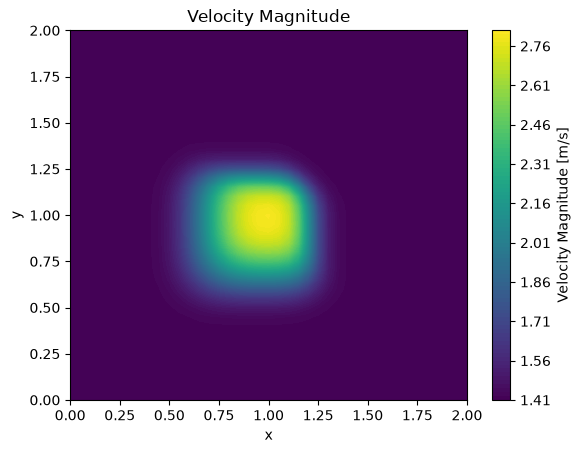

In [48]:
fig, ax = plt.subplots()
contour = ax.contourf(X, Y, U[-1][2], levels=100, cmap=cm.viridis)
colobar = fig.colorbar(contour, ax=ax, label="Velocity Magnitude [m/s]", format="%.2f")
title_text = ax.set_title('Velocity Magnitude')
ax.set_xlabel("x")
ax.set_ylabel("y")
plt.show()

frames = nt

def gif_func(frame):
    contour = ax.contourf(X, Y, U[frame][2], levels=100, cmap=cm.viridis)
    title_text = ax.set_title(f'Velocity Magnitude at time step {frame}')

anim = animation.FuncAnimation(fig, gif_func, frames= range(frames), interval=100, blit=True)
anim.save('burgers_equation.gif', writer='imagemagick', fps=5)
